# 06 — Reject Inference

In [1]:
# Cell 1 — setup
import sys, pathlib
sys.path.append(str(pathlib.Path.cwd().parent / "src"))
from scorelab import config, data
con = data.connect()            # read-only DuckDB connection to data/lc.duckdb

In [2]:
# Cell 2 — sanity check
print(con.sql("SHOW TABLES"))
print(con.sql("SELECT COUNT(*) AS n, MIN(issue_d), MAX(issue_d) FROM accepted"))

┌─────────────────┐
│      name       │
│     varchar     │
├─────────────────┤
│ accepted        │
│ rejected        │
│ v_accepted_asof │
│ v_split         │
│ v_target        │
└─────────────────┘

┌─────────┬──────────────┬──────────────┐
│    n    │ min(issue_d) │ max(issue_d) │
│  int64  │     date     │     date     │
├─────────┼──────────────┼──────────────┤
│ 2260668 │ 2007-06-01   │ 2018-12-01   │
└─────────┴──────────────┴──────────────┘



In [3]:
# Cell 3 — common imports and settings for this notebook
import json, warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
from scorelab import target, attributes as A, binning as B, scorecard as S, validation as V, fairness as F
from scorelab import challengers as C, reject_inference as R, monitoring as M, report as REP
MODELS = config.MODELS_DIR; MODELS.mkdir(exist_ok=True)
SAMPLE_FRAC = None     # None = full data (recommended for the fitting notebooks); e.g. 0.10 for a quick pass
cols = [r[0] for r in con.execute("DESCRIBE v_target").fetchall()]
assert "label" in cols, "v_target is the old stub: close this kernel and run `python scripts/refresh_views.py`"
def load_frame(splits=("train", "validate", "oot"), **kw):
    """Observable, non-excluded loans with attributes built; indeterminates dropped unless asked."""
    f = target.modeling_frame(con, splits=splits, sample_frac=SAMPLE_FRAC, **kw)
    return A.build_attributes(f)
MEANINGS = {a.name: a.meaning for a in A.REGISTRY}
DIRECTIONS = {a.name: a.direction for a in A.REGISTRY}

## What this notebook settles

Whether and how reject inference changes the card, and what population each number in the pilot report describes. The real rejected file has no bureau attributes, so the methods are validated on a **simulated reject region with hidden truth**: the riskiest share of the accepted population by FICO is treated as declined, the known-good-bad (KGB) card is built on the rest, each inference method fills the declines (hard cutoff, parceling, fuzzy augmentation, and the semi-supervised view: self-training), and every variant is compared on the full population where the truth is known.

Decisions: **L — reject rate and incumbent for the simulation**, **M — which method, if any, is defensible for the pilot**.

In [4]:
frame = load_frame()
tr, va, oot = (frame[frame.split == s] for s in ("train", "validate", "oot"))
card, specs = S.load_card(MODELS / "champion"); attrs = card.attributes
def fit_fn(f):
    Wf = B.transform_woe(f, {a: specs[a] for a in attrs})
    return S.fit_logistic(Wf, f["bad"], attrs, sample_weight=f["weight"] if "weight" in f else None)
def score_fn(c, f): return S.score(f, c, specs)["p_bad"].to_numpy()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,fico_band,n_rejected,n_accepted,share_rejected,share_accepted,acceptance_rate
0,300,194.0,0.0,0.0000,0.0000,0.0000
1,320,158.0,0.0,0.0000,0.0000,0.0000
2,340,415.0,0.0,0.0001,0.0000,0.0000
3,360,224.0,0.0,0.0001,0.0000,0.0000
4,380,217.0,0.0,0.0001,0.0000,0.0000
5,400,464.0,0.0,0.0001,0.0000,0.0000
6,420,1276.0,0.0,0.0003,0.0000,0.0000
7,440,4025.0,0.0,0.0010,0.0000,0.0000
8,460,11862.0,0.0,0.0030,0.0000,0.0000
9,480,21883.0,0.0,0.0056,0.0000,0.0000


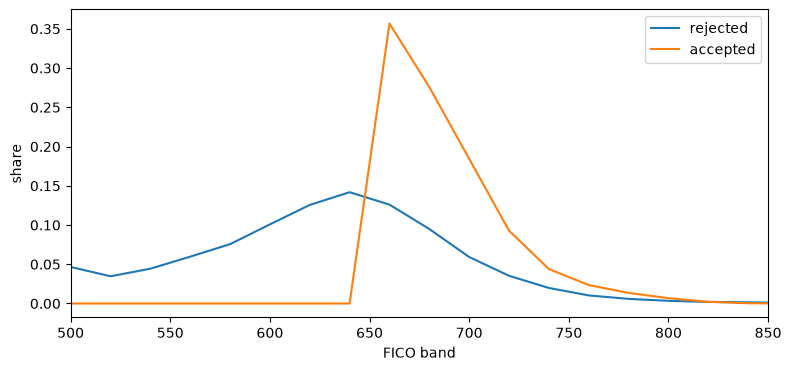

In [5]:
# Evidence — how far the booked population is from through-the-door, from the real rejected file
ttd = R.through_the_door_profile(con, years=tuple(config.TRAIN_VINTAGES) + (config.VALIDATE_VINTAGE, config.OOT_VINTAGE))
display(ttd)
fig, ax = plt.subplots(figsize=(9, 4)); ax.plot(ttd.fico_band, ttd.share_rejected, label="rejected"); ax.plot(ttd.fico_band, ttd.share_accepted, label="accepted")
ax.set_xlim(500, 850); ax.set_xlabel("FICO band"); ax.set_ylabel("share"); ax.legend(); plt.show()

### Decision L — Simulation design

Reject rate (Lending Club's real acceptance rate is far lower than any lender pilot; the simulation should mimic a lender's cutoff, 10–30%), and the incumbent used to decline (FICO midpoint, as in the pilot).

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**Keep `REJECT_RATE = 0.20` with the FICO midpoint as the declining incumbent.**

- **The real gap is far larger than any pilot's.** In the rejected file, every applicant below a FICO band of 660 was rejected: no accepted loan sits below it, and acceptance runs at only 39–49% between bands 660 and 800. A lender pilot declines 10–30%, so the simulation should mimic that cutoff, not Lending Club's.
- **20% gives a usable contrast.** The simulated declines have a hidden bad rate of 14.07% against 9.71% for the approved. That is enough difference for the methods to be told apart, while 80% of the development sample keeps its labels.
- **FICO midpoint as the incumbent** matches the pilot in NB08, so the declined region here is the region the pilot's incumbent would decline.

In [6]:
REJECT_RATE = 0.20
dev = pd.concat([tr, va])
sim = R.simulate_reject_region(dev, incumbent="fico_mid", reject_rate=REJECT_RATE)
print(f"declined {sim.declined.mean():.1%} · true bad rate declined {sim.loc[sim.declined, 'bad_hidden'].mean():.2%} · approved {sim.loc[~sim.declined, 'bad_hidden'].mean():.2%}")
cmp = R.compare_methods(sim, fit_fn, score_fn, oot, multipliers=(1.0, 1.5, 2.0))
display(cmp); cmp.to_csv(config.DOCS_DIR / "exhibits" / "reject_inference_comparison.csv", index=False)

declined 20.0% · true bad rate declined 14.07% · approved 9.71%


,method,inferred_bad_rate_declined,true_bad_rate_declined,gini_through_the_door,gini_approved_only,gini_declined_only,gini_eval_set
0,kgb_only,NaN,0.1407,0.2927,0.2932,0.2283,0.2859
1,hard_cutoff,0.2430,0.1407,0.2927,0.2928,0.2302,0.2862
2,parceling_x1,0.1261,0.1407,0.2927,0.2932,0.2283,0.2858
3,parceling_x1.5,0.1893,0.1407,0.2920,0.2926,0.2255,0.2851
4,parceling_x2,0.2519,0.1407,0.2905,0.2912,0.2226,0.2836
5,fuzzy_augmentation,0.1262,0.1407,0.2927,0.2932,0.2283,0.2859
6,self_training,0.1732,0.1407,0.2915,0.2909,0.2327,0.2848


In [7]:
# Evidence — the semi-supervised view: self-training, round by round
# Each round labels a quarter of the declines from the confident tails of the current card (riskiest
# k*mean(p) as bad, safest as good), then refits on approved + pseudo-labelled rows. The accuracy
# column uses the hidden truth, which a real lender would not have.
st_aug, st_hist = R.self_training(sim, fit_fn, score_fn, step=0.25)
display(st_hist.round(4))
print(f"self-training: inferred bad rate on declines {st_aug.loc[st_aug.declined, 'bad'].mean():.2%} vs hidden truth {sim.loc[sim.declined, 'bad_hidden'].mean():.2%}")

,round,n_pseudo_labelled,pseudo_bad_rate,mean_p_remaining,n_remaining,pseudo_label_accuracy
0,1,38929,0.1262,0.1262,116784,0.8347
1,2,38929,0.1555,0.1555,77855,0.7860
2,3,38929,0.1874,0.1874,38926,0.7403
3,4,38926,0.2236,0.2236,0,0.6833


self-training: inferred bad rate on declines 17.32% vs hidden truth 14.07%


In [8]:
# Evidence — do decisions change? KGB card vs fuzzy-augmented card at the pilot approval rate
kgb = fit_fn(sim[~sim.declined].assign(weight=1.0))
p_dec = score_fn(kgb, sim[sim.declined])
aug = fit_fn(R.fuzzy_augmentation(sim, p_dec))
display(R.swap_vs_kgb(sim, score_fn(kgb, sim), score_fn(aug, sim), approval_rate=config.APPROVAL_RATE_FOR_SWAP))

,n,true_bad_rate
approved_by_both,544996,0.0792
swap_in_augmented,0,NaN
swap_out_augmented,0,NaN
declined_by_both,233569,0.1681


### Decision M — What the pilot reports

Given the comparison: does any method, including self-training, recover rank order on the declines that the KGB card does not? Is the inferred bad rate on declines close to the hidden truth? State which population (booked only / augmented) the pilot numbers describe, and whether to show both.

**Your reasoning:**

**DRAFT** (Claude, 2026-11-01, from this notebook's full-data outputs; for review). The notebook ran with the defaults in the code cells; this draft says whether to keep them.

**Report the pilot on the booked population only. Show the reject-inference comparison as a sensitivity, not as an adjusted result.**

**No method recovers rank order on the declines materially better than the known-good-bad (KGB) card:**

| Method | Gini on declines | Gini on the 2016 evaluation set |
|---|---:|---:|
| KGB only | 0.2283 | 0.2859 |
| Self-training | 0.2327 | 0.2848 |
| Hard cutoff | 0.2302 | 0.2862 |
| Parceling ×1 | 0.2283 | 0.2858 |
| Parceling ×2 | 0.2226 | 0.2836 |
| Fuzzy augmentation | 0.2283 | 0.2859 |

Self-training gains 0.0044 on the declines and loses 0.0011 on 2016; all methods stay within 0.2836–0.2862 on 2016.

**No method gets the declines' bad rate right.** The hidden truth is 14.07%.
- Parceling ×1 (12.61%) and fuzzy augmentation (12.62%) understate it.
- Self-training (17.32%), parceling ×1.5 (18.93%), hard cutoff (24.30%) and parceling ×2 (25.19%) overstate it.
- Self-training drifts upward round by round: the pseudo-bad rate rises from 12.62% to 22.36%, while the accuracy of the pseudo-labels falls from 83.5% to 68.3%.

**Fuzzy augmentation changes no decision.** At a 70% approval rate the augmented card swaps in 0 and swaps out 0 applicants against the KGB card. This is expected: weighting each decline by the KGB card's own probability refits the same model.

**What the pilot numbers describe:** booked loans (Lending Club approvals). NB08 says so in its caveats.